In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from scipy import stats

random.seed(42)

from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, LeaveOneOut, StratifiedKFold
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier

from sklearn.linear_model import Lasso, LogisticRegression, SGDClassifier
from sklearn.metrics import roc_curve, auc, roc_auc_score
import feyn
from feyn.plots.interactive import interactive_activation_flow
feyn._qlattice._USE_V2_API=True
feyn.__version__

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.feature_selection import RFE, mutual_info_classif, SelectKBest, f_classif,chi2, mutual_info_classif
from sklearn.metrics import log_loss, accuracy_score
from mrmr import mrmr_classif
from sklearn.base import clone
import itertools
from sklearn.pipeline import Pipeline

import concurrent.futures 
from concurrent.futures import ThreadPoolExecutor, as_completed

This version of Feyn and the QLattice is available for academic, personal, and non-commercial use. By using the community version of this software you agree to the terms and conditions which can be found at https://abzu.ai/eula.

In [2]:
from fuzzywuzzy import process
df_original = pd.read_csv('../data/merged_data/omics_aibl_demo.csv',index_col=0)
df_updated = pd.read_csv('../data/merged_data/omics_aibl_demo_impute.csv',index_col=0)

original_columns = df_original.columns.tolist()
updated_columns = df_updated.columns.tolist()

# Create a mapping based on fuzzy string matching
mapping = {}
for orig_col in original_columns:
    match, score = process.extractOne(orig_col, updated_columns)
    mapping[orig_col] = match

# Convert the mapping into a DataFrame
mapping_df = pd.DataFrame(list(mapping.items()), columns=['Original_Name', 'Updated_Name'])
mapping_dict = dict(zip(mapping_df['Updated_Name'], mapping_df['Original_Name']))


In [3]:
mapping_df[mapping_df['Original_Name'].str.contains('FA')].head(2)

,Original_Name,Updated_Name
194,FA hydroxy(7:0),FA.hydroxy.7.0.
262,FA methyl(8:0),FA.methyl.8.0.


In [4]:
omics_df_normalise_no_missing = pd.read_csv('../data/merged_data/omics_aibl_demo_impute.csv',index_col=0)
# print(omics_df_normalise_no_missing.select_dtypes(include=['object', 'category']).columns)
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['Gender','Collection','AIBL.ID','Demographic.ApoE.genotype','Demographic.Years.of.Education',
                                                                    'Demographic.Primary.Occupation','Demographic.Retirement.Status',
                                                                    'Demographic.Current.Marital.Status', 'Demographic.Country.of.Birth',], axis=1)
omics_df_normalise_no_missing['label'] = omics_df_normalise_no_missing['label'].replace({"H": 1, "N": 0})
omics_df_normalise_no_missing['Demographic.Sex'] = omics_df_normalise_no_missing['Demographic.Sex'].replace({"Male": 1, "Female": 0})
omics_df_normalise_no_missing.rename(columns={col: col.replace(':', '_') for col in omics_df_normalise_no_missing.columns if ':' in col}, inplace=True)

columns_to_drop_no_missing = omics_df_normalise_no_missing[['label', 'APOE4','Demographic.Sex']]
one_hot_encoded_handedness = pd.get_dummies(omics_df_normalise_no_missing['Demographic.Handedness'], prefix='Demographic.Handedness')
one_hot_encoded_handedness_names=one_hot_encoded_handedness.columns.to_list()
omics_df_normalise_no_missing = omics_df_normalise_no_missing.drop(['label', 'APOE4','Demographic.Sex', 'Demographic.Handedness'], axis=1)

# # # ##### MinMax scaling
scaler = MinMaxScaler()
normalized_features_no_missing = pd.DataFrame(scaler.fit_transform(omics_df_normalise_no_missing), columns=omics_df_normalise_no_missing.columns)
columns_to_drop_no_missing
omics_demo_normalise_df_no_missing = pd.concat([normalized_features_no_missing, columns_to_drop_no_missing.reset_index(drop=True), one_hot_encoded_handedness.reset_index(drop=True)], axis=1)



### Functions for model construction/evaluation and plots
Model considered: Logistic Regression with Lasso/Ridge penalty; SVM; Random Forest;  QLattice; 

In [5]:
from sklearn.base import BaseEstimator, ClassifierMixin

class QLatticeClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, n_epochs, max_complexity,stypes=None):
        self.n_epochs = n_epochs
        self.max_complexity = max_complexity
        self.model = None  
        self.stypes = stypes

    def fit(self, data):
        ql = feyn.QLattice(random_seed=42)
        models = ql.auto_run(data, stypes=self.stypes,n_epochs=self.n_epochs, output_name='label', kind='classification', criterion='aic', max_complexity=self.max_complexity)
        self.model = models[0]
        return self

    def predict_proba(self, X):
        if self.model is not None:
            return self.model.predict(X)
        else:
            raise Exception("Model is not trained yet.")

    def predict(self, X):
        proba = self.predict_proba(X)
        return [1 if p > 0.5 else 0 for p in proba] # p is the probability of the positive class (class '1')
    
    def get_features(self):
        """ Extracts and returns the features used by the QLattice model """
        if self.model is not None:
            return list(self.model.features)
        else:
            raise Exception("Model is not trained yet. No features available.")

In [6]:
def perform_feature_selection(method, params, model, X, y, rng=None):
    if method == "rfe":
        print("Do RFE feature Selection")
        selector = RFE(model, n_features_to_select=params, step=50)
        selector.fit(X, y)
        selected_features = X.columns[selector.get_support(indices=True)]
    elif method == 'mrmr':
        print("Do MRMR feature selection")
        selected_features = mrmr_classif(X=X, y=y, K=params)
    elif method == 'select_k_best':
        print("Do SelectKBest feature selection")
        selector = SelectKBest(score_func=f_classif, k=params)
        selector.fit(X, y)
        selected_features = X.columns[selector.get_support(indices=True)]
    elif method == 'correlation':
        print("Do Correlation-Based feature selection")
        target_correlation = X.apply(lambda col: col.corr(pd.Series(y)))
        selected_features = target_correlation.abs().nlargest(params).index.tolist()
    elif method == 'mutual_info':
        print("Do Mutual Information feature selection")
        mi = mutual_info_classif(X, y, random_state=rng.integers(0, 100000) if rng else None)
        mi_series = pd.Series(mi, index=X.columns)
        selected_features = mi_series.nlargest(params).index.tolist()
    else:
        selected_features = X.columns 
    return selected_features

In [7]:
def parameter_tuning_cf(model_type, params, X_train, y_train, X_test, y_test, feature_selection_method=None, num_features = None, rng=None):
    ## initialise the models
    if model_type == 'random_forest':
        n_estimators, max_depth, min_samples_split, min_samples_leaf = params
        model = RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                       min_samples_split=min_samples_split, min_samples_leaf=min_samples_leaf,
                                       class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'svm':
        C, kernel, gamma = params
        model = SVC(C=C, kernel=kernel, gamma=gamma, class_weight='balanced', probability=True, random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'logistic_regression':
        C, penalty, solver = params
        if penalty == 'elasticnet' and solver != 'saga':
            return
        if penalty == 'elasticnet' and solver == 'saga':
            model = LogisticRegression(C=C, penalty=penalty, l1_ratio=0.5, solver=solver, class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
        else:
            model = LogisticRegression(C=C, penalty=penalty, solver=solver, class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
    elif model_type == 'sgd':
        alpha, penalty, l1_ratio, loss = params
        if penalty == 'elasticnet' or (penalty in ['l1', 'l2'] and l1_ratio == 0.15):
            model = SGDClassifier(alpha=alpha, penalty=penalty, l1_ratio=l1_ratio, loss=loss,
                                class_weight='balanced', random_state=rng.integers(0, 100000) if rng else 42)
        else:
            return
    elif model_type == 'qlattice':
        n_epochs, max_complexity = params
        model = QLatticeClassifier(n_epochs=n_epochs, max_complexity=max_complexity)

    if feature_selection_method == "rfe":
        # print("only rfe feature selection")
        selected_features = perform_feature_selection(feature_selection_method, num_features, model, X_train, y_train)
        X_train, X_test = X_train[selected_features], X_test[selected_features]


    if model_type == 'qlattice':
        train = pd.concat([X_train, y_train], axis=1)
        model.fit(train)
        test = pd.concat([X_test, y_test], axis=1)
        y_pred_prob = model.predict_proba(test)
        test_auc = roc_auc_score(y_test, y_pred_prob)
    else:
        model.fit(X_train, y_train)
        y_pred_prob = model.predict_proba(X_test)[:, 1]
        test_auc = roc_auc_score(y_test, y_pred_prob)

    return {
        'model': model, 
        'params': params, 
        'test_auc': test_auc, 
        'feature_selection_method': feature_selection_method,
        'num_features': num_features, 
        'selected_features':  selected_features if feature_selection_method == "rfe" else None
    }

In [8]:
def tune_model_parameters(model_name, param_combinations, X, y, n_splits=5, feature_selection_method=None, num_features = None, rng=None):
    results_list = []
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=rng.integers(0, 100000) if rng else 42)
    for train_ix, test_ix in skf.split(X, y):
        X_train, X_test = X.iloc[train_ix], X.iloc[test_ix]
        y_train, y_test = y.iloc[train_ix], y.iloc[test_ix]
        if feature_selection_method and feature_selection_method != "rfe":
            selected_features = perform_feature_selection(feature_selection_method, num_features, None, X_train, y_train, rng=rng)
            X_train, X_test = X_train[selected_features], X_test[selected_features]

        for params in param_combinations:
            result = parameter_tuning_cf(model_name, params, X_train, y_train, X_test, y_test, feature_selection_method, num_features, rng=rng)
            if result is not None:
                results_list.append({'params': params, 'test_auc': result['test_auc']})
            

    results_df = pd.concat([pd.DataFrame([result]) for result in results_list], ignore_index=True)
    mean_auc_by_parameter = results_df.groupby('params')['test_auc'].mean().reset_index()
    best_parameters_row = mean_auc_by_parameter.sort_values(by='test_auc', ascending=False).iloc[0]
    # display(best_parameters_row)

    best_model = parameter_tuning_cf(model_name, best_parameters_row['params'], X, y, X, y)['model']
    
    return best_model, best_parameters_row


In [9]:
def evaluate_model_with_stratified_cf(df, model_type,param_combinations, inner_n_split = 5, outer_n_split = 5, feature_selection_method=None, num_features = None,random_seed=42, rng=None):
    skf = StratifiedKFold(n_splits=outer_n_split, shuffle=True, random_state=random_seed)
    y_true_list, y_pred_list, y_pred_prob_list, auc_scores = [], [], [], []
    learning_curve = {'train_loss': [], 'test_loss': [], 
                        'train_acc':[], 'test_acc':[],
                        'train_auc':[]}

    X, y=df.drop('label', axis=1), df['label']
    feature_names = X.columns.to_list()
    feature_selection_count = {feature: 0 for feature in X.columns}
    feature_coefficient_sum = {feature: 0.0 for feature in X.columns} 
    total_feature_count = 0

    for train_val_index, test_index in skf.split(X, y):
        X_train_val, X_test = X.iloc[train_val_index], X.iloc[test_index]
        y_train_val, y_test = y.iloc[train_val_index], y.iloc[test_index]

        ## here do the inner 10-fold cv to do the hyperparameter tunning +/ feature selection methods => get the best model hyperparameter
        best_model, best_parameters_row= tune_model_parameters(model_type, param_combinations, X_train_val, y_train_val, inner_n_split, feature_selection_method, num_features)

        ## retrain the model on the train_val data
        selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X_train_val, y_train_val)
        X_train_selected = X_train_val.loc[:, selected_features]
        X_test_selected = X_test.loc[:, selected_features]
        if model_type == 'qlattice':
            train_val = pd.concat([X_train_selected, y_train_val], axis=1)
            best_model.fit(train_val)
            y_test_pred = best_model.predict(train_val)
            test = pd.concat([X_test_selected, y_test], axis=1)
            y_test_pred_prob = best_model.predict_proba(test)
            y_test_pred = best_model.predict(test)
            selected_features = best_model.get_features()

            y_train_pred_prob = best_model.predict_proba(train_val)
            y_train_pred = best_model.predict(train_val)
            
        else:
            best_model.fit(X_train_selected, y_train_val)
            y_test_pred = best_model.predict(X_test_selected).tolist()
            y_test_pred_prob = best_model.predict_proba(X_test_selected)[:, 1].tolist()
            y_train_pred_prob = best_model.predict_proba(X_train_selected)[:, 1].tolist()
            y_train_pred = best_model.predict(X_train_selected).tolist()

            if hasattr(best_model, 'coef_'):
                coefs = abs(best_model.coef_[0])  ########## add the absolute value here
                for i, feature in enumerate(selected_features):
                    feature_coefficient_sum[feature] += coefs[i]
                    
            if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
                coefs = best_model.coef_[0]
                selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

            if model_type == 'random_forest':
                root_features = []
                for estimator in best_model.estimators_:
                    root_feature_index = estimator.tree_.feature[0]
                    root_feature_name = X_train_selected.columns[root_feature_index]
                    root_features.append(root_feature_name)
        
        train_loss = log_loss(y_train_val, y_train_pred_prob)
        test_loss = log_loss(y_test, y_test_pred_prob)
        train_acc = accuracy_score(y_train_val, y_train_pred)
        test_acc = accuracy_score(y_test, y_test_pred)
        learning_curve['train_loss'].append(train_loss)
        learning_curve['test_loss'].append(test_loss)
        learning_curve['train_acc'].append(train_acc)
        learning_curve['test_acc'].append(test_acc)
        train_auc = roc_auc_score(y_train_val, y_train_pred_prob)
        learning_curve['train_auc'].append(train_auc)
            
        fold_auc = roc_auc_score(y_test, y_test_pred_prob)
        auc_scores.append(fold_auc)
        y_true_list.extend(y_test.tolist())
        y_pred_list.extend(y_test_pred)
        y_pred_prob_list.extend(y_test_pred_prob)

        for ft in selected_features:
            feature_selection_count[ft] += 1
        total_feature_count += len(selected_features)

    # Prepare Feature Selection DataFrame
    feature_selection_df = pd.DataFrame(list(feature_selection_count.items()), columns=['Feature', 'Count'])
    feature_selection_df = feature_selection_df.sort_values(by='Count', ascending=False)
    feature_selection_df = feature_selection_df[feature_selection_df['Count'] > 0]
    average_feature_count = total_feature_count/10

    feature_coefficient_df = pd.DataFrame(list(feature_coefficient_sum.items()), columns=['Feature', 'CoefficientSum'])
    feature_coefficient_df = feature_coefficient_df.sort_values(by='CoefficientSum', ascending=False)
    feature_coefficient_df = feature_coefficient_df[feature_coefficient_df['CoefficientSum'] != 0]            
    return y_true_list, y_pred_prob_list, y_pred_list, feature_selection_df, average_feature_count, feature_coefficient_df, auc_scores, learning_curve

In [10]:
from concurrent.futures import ThreadPoolExecutor
import random
import numpy as np
from sklearn.metrics import roc_auc_score
from scipy import stats


def run_multiple_evaluations_parallel(df, model_type, param_combinations, n_runs=10, inner_n_split=5, outer_n_split=5, feature_selection_method=None, num_features=None, global_seed=42):
    all_auc_scores = []
    all_y_true = []
    all_y_pred_prob = []
    all_results = []

    random.seed(global_seed)  # Set the global seed
    seeds = [random.randint(0, 100000) for _ in range(n_runs)]

    def evaluate_run(run_seed):
        rng = np.random.default_rng(run_seed)  # Create a random number generator with the given seed
        y_true, y_pred_prob, y_pred, feature_selection_df, avg_feature_count, feature_coef_df, auc_scores, learning_curve = evaluate_model_with_stratified_cf(
            df, model_type, param_combinations, inner_n_split=inner_n_split, outer_n_split=outer_n_split,
            feature_selection_method=feature_selection_method, num_features=num_features, random_seed=run_seed, rng=rng
        )
        result = {
            'run_seed': run_seed,
            'y_true': y_true,
            'y_pred_prob': y_pred_prob,
            'y_pred': y_pred,
            'feature_selection_df': feature_selection_df,
            'avg_feature_count': avg_feature_count,
            'feature_coef_df': feature_coef_df,
            'auc_scores_fold': auc_scores,
            'auc_scores_all': [roc_auc_score(y_true, y_pred_prob)],
            'learning_curve': learning_curve
        }
        return result, y_true, y_pred_prob, auc_scores

    with ThreadPoolExecutor(max_workers=5) as executor:  # utilize parallelism
        futures = [executor.submit(evaluate_run, seed) for seed in seeds]
        for future in futures:
            result, y_true, y_pred_prob, auc_scores = future.result()
            all_results.append(result)
            all_y_true.extend(y_true)
            all_y_pred_prob.extend(y_pred_prob)
            all_auc_scores.extend([roc_auc_score(y_true, y_pred_prob)])

    # Calculate overall AUC, median AUC and IQR based on individual fold AUC scores
    median_auc = np.median(all_auc_scores)
    iqr_auc = stats.iqr(all_auc_scores)
    auc_25th = np.percentile(all_auc_scores, 25)
    auc_75th = np.percentile(all_auc_scores, 75)
    overall_auc = roc_auc_score(all_y_true, all_y_pred_prob)

    return all_results, overall_auc, median_auc, iqr_auc, (auc_25th, auc_75th)

In [11]:
def extract_results(all_results, key):
    extracted_data = []
    if key == 'feature_selection_df':
        feature_counts = {}
        for result in all_results:
            for feature, count in result['feature_selection_df'].values:
                if feature in feature_counts:
                    feature_counts[feature] += count
                else:
                    feature_counts[feature] = count
        extracted_data = pd.DataFrame(list(feature_counts.items()), columns=['Feature', 'Total Count'])
    elif key == 'feature_coef_df':
        coef_sums = {}
        for result in all_results:
            for feature, coef_sum in result['feature_coef_df'].values:
                if feature in coef_sums:
                    coef_sums[feature] += coef_sum
                else:
                    coef_sums[feature] = coef_sum
        extracted_data = pd.DataFrame(list(coef_sums.items()), columns=['Feature', 'Coefficient Sum'])
    elif key in ['y_true', 'y_pred_prob', 'y_pred', 'auc_scores_fold', 'auc_scores_all']:
        for result in all_results:
            extracted_data.extend(result[key])
    return extracted_data

In [12]:
def evaluate_full_dataset(df, model_type, param_combinations, feature_selection_method=None, num_features=None):
    X, y = df.drop('label', axis=1), df['label']
    feature_names = X.columns.to_list()
    feature_coefficient_sum = {feature: 0.0 for feature in X.columns}

    # Tune model parameters using the entire dataset
    best_model, best_parameters_row = tune_model_parameters(model_type, param_combinations, X, y, n_splits=5, feature_selection_method=feature_selection_method, num_features=num_features)

    # Perform feature selection if specified
    selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X, y)
    X_selected = X.loc[:, selected_features]


    # Fit the model on the entire dataset
    if model_type == 'qlattice':
        data = pd.concat([X_selected, y], axis=1)
        best_model.fit(data)
        y_pred = best_model.predict(data)
        y_pred_prob = best_model.predict_proba(data)
        selected_features = best_model.get_features()
    else:
        best_model.fit(X_selected, y)
        y_pred = best_model.predict(X_selected).tolist()
        y_pred_prob = best_model.predict_proba(X_selected)[:, 1].tolist()

    # Extract feature coefficients if available
    if hasattr(best_model, 'coef_'):
        coefs = best_model.coef_[0]  ########## add the absolute value here
        for i, feature in enumerate(selected_features):
            feature_coefficient_sum[feature] += coefs[i]
            
    if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
        coefs = best_model.coef_[0]
        selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

    if model_type == 'random_forest':
        root_features = []
        for estimator in best_model.estimators_:
            root_feature_index = estimator.tree_.feature[0]
            root_feature_name = X_selected.columns[root_feature_index]
            root_features.append(root_feature_name)

    # Prepare feature coefficient DataFrame
    feature_coefficient_df = pd.DataFrame(list(feature_coefficient_sum.items()), columns=['Feature', 'CoefficientSum'])
    feature_coefficient_df = feature_coefficient_df.sort_values(by='CoefficientSum', ascending=False)
    feature_coefficient_df = feature_coefficient_df[feature_coefficient_df['CoefficientSum'] != 0]

    return y.tolist(), y_pred_prob, y_pred, feature_coefficient_df

In [13]:
def evaluate_10_splits(df, model_type, param_combinations, feature_selection_method=None, num_features=None):
    auc_scores = []

    # Perform the 10 splits
    for _ in range(10):
        # Split dataset into training and test sets (60-40 split)
        train_df, test_df = train_test_split(df, test_size=0.4, random_state=np.random.randint(10000))
        X_train, y_train = train_df.drop('label', axis=1), train_df['label']
        X_test, y_test = test_df.drop('label', axis=1), test_df['label']
        feature_names = X_train.columns.to_list()
        feature_coefficient_sum = {feature: 0.0 for feature in X_train.columns}

        # Tune model parameters using the training dataset only
        best_model, best_parameters_row = tune_model_parameters(
            model_type, param_combinations, X_train, y_train, n_splits=5, 
            feature_selection_method=feature_selection_method, num_features=num_features
        )

        # Perform feature selection if specified
        selected_features = perform_feature_selection(feature_selection_method, num_features, best_model, X_train, y_train)
        X_train_selected = X_train.loc[:, selected_features]
        X_test_selected = X_test.loc[:, selected_features]

        # Fit the model on the training dataset
        if model_type == 'qlattice':
            data_train = pd.concat([X_train_selected, y_train], axis=1)
            best_model.fit(data_train)
            y_pred_prob = best_model.predict_proba(X_test_selected)
        else:
            best_model.fit(X_train_selected, y_train)
            y_pred_prob = best_model.predict_proba(X_test_selected)[:, 1]

        # Calculate AUC and store the result
        auc_score = roc_auc_score(y_test, y_pred_prob)
        auc_scores.append(auc_score)

        # Extract feature coefficients if available
        if hasattr(best_model, 'coef_'):
            coefs = abs(best_model.coef_[0])  # Using absolute value of coefficients
            for i, feature in enumerate(selected_features):
                feature_coefficient_sum[feature] += coefs[i]

        if isinstance(best_model, LogisticRegression) and best_model.penalty == 'l1':
            coefs = best_model.coef_[0]
            selected_features = [feature_names[i] for i, coef in enumerate(coefs) if coef != 0]

        if model_type == 'random_forest':
            root_features = []
            for estimator in best_model.estimators_:
                root_feature_index = estimator.tree_.feature[0]
                root_feature_name = X_train_selected.columns[root_feature_index]
                root_features.append(root_feature_name)

    return auc_scores


In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample

def auc_plot(yt, ypp):
    y_true = np.array(yt)
    y_scores = np.array(ypp)
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    plt.figure(figsize=(4, 3)) 
    lw = 2  # Line width
    plt.plot(fpr, tpr, color='darkorange', lw=lw, label=f'ROC curve (AUC = {roc_auc:.2f})')
    # plt.fill_between(fpr, tpr_lower, tpr_upper, color='grey', alpha=0.3, label=f'{ci}% Confidence interval')
    plt.plot([0, 1], [0, 1], color='navy', lw=lw, linestyle='--')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic')
    plt.legend(loc="lower right")
    plt.show()

In [15]:
import numpy as np
from sklearn.metrics import roc_curve, auc, confusion_matrix, accuracy_score
from sklearn.utils import resample

def compute_evaluation_matrix(y_true, y_scores, n_bootstraps=1000, ci=95):
    y_true = np.array(y_true)
    y_scores = np.array(y_scores)

    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    original_cm = confusion_matrix(y_true, y_scores.round())
    original_accuracy = accuracy_score(y_true, y_scores.round())
    results = {
        "Confusion Matrix\n": original_cm,
        "Accuracy": original_accuracy,
        "Original AUC": roc_auc,
    }

    return results

In [16]:
def plot_boxplot(data):
    sns.boxplot(data=data)
    plt.xlabel('Value')
    plt.title('Violin Plot of Distribution')
    plt.show()

## Demographic only

In [17]:
model_demo_df = omics_demo_normalise_df_no_missing.copy()
demo_lst =[ 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age'] 
model_demo_df = model_demo_df[demo_lst+['label']]
model_demo_df.columns

Index(['Demographic.Sex', 'Demographic.Years.of.Education.Exact', 'Age',
       'label'],
      dtype='object')

In [18]:
model_demo_df_M = model_demo_df[model_demo_df['Demographic.Sex']==1]
model_demo_df_M = model_demo_df_M.drop(['Demographic.Sex'], axis=1)
model_demo_df_F = model_demo_df[model_demo_df['Demographic.Sex']==0]
model_demo_df_F = model_demo_df_F.drop(['Demographic.Sex'], axis=1)

#### LR-Full No feature selection

In [19]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo, overall_auc_lr_demo, median_auc_lr_demo, iqr_auc_lr_demo, iqr13_auc_lr_demo= run_multiple_evaluations_parallel(model_demo_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [20]:
results_lr_demo_auc_scores_all = extract_results(results_lr_demo, 'auc_scores_all')
overall_evaluation_df = pd.DataFrame({'Model': "LR (Demographic)", "AUC": results_lr_demo_auc_scores_all})

Overall AUC: 0.42193246753246755, Median AUC: 0.43012987012987014, IQR : 0.05097402597402595, IQ1-IQ3: (0.39623376623376627, 0.4472077922077922)


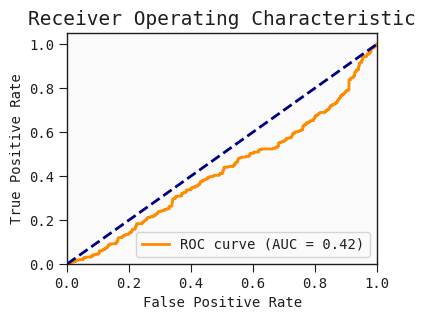

In [21]:
y_true_list_lr_demo = extract_results(results_lr_demo, 'y_true')
y_pred_prob_list_lr_demo= extract_results(results_lr_demo, 'y_pred_prob')
y_pred_list_lr_demo= extract_results(results_lr_demo, 'y_pred')
feature_selection_df_lr_demo= extract_results(results_lr_demo, 'feature_selection_df')
feature_sum_coef_df_lr_demo= extract_results(results_lr_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo}, Median AUC: {median_auc_lr_demo}, IQR : {iqr_auc_lr_demo}, IQ1-IQ3: {iqr13_auc_lr_demo}") 
auc_plot(extract_results(results_lr_demo, 'y_true'), extract_results(results_lr_demo, 'y_pred_prob'))

#### LR-Female No feature selection

In [22]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demoF, overall_auc_lr_demoF, median_auc_lr_demoF, iqr_auc_lr_demoF, iqr13_auc_lr_demoF = run_multiple_evaluations_parallel(model_demo_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5388879456706281, Median AUC: 0.5458404074702886, IQR : 0.08637521222410871, IQ1-IQ3: (0.4866298811544991, 0.5730050933786078)


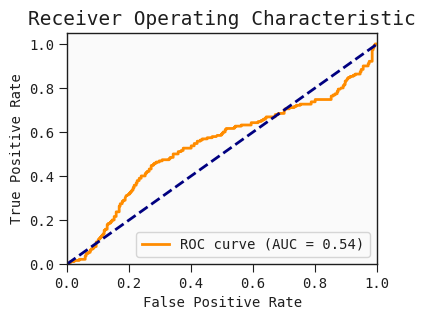

In [23]:
results_lr_demoF_auc_scores_all = extract_results(results_lr_demoF, 'auc_scores_all')
y_true_list_lr_demoF = extract_results(results_lr_demoF, 'y_true')
y_pred_prob_list_lr_demoF= extract_results(results_lr_demoF, 'y_pred_prob')
y_pred_list_lr_demoF= extract_results(results_lr_demoF, 'y_pred')
feature_selection_df_lr_demoF= extract_results(results_lr_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_demoF= extract_results(results_lr_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demoF}, Median AUC: {median_auc_lr_demoF}, IQR : {iqr_auc_lr_demoF}, IQ1-IQ3: {iqr13_auc_lr_demoF}") 
auc_plot(extract_results(results_lr_demoF, 'y_true'), extract_results(results_lr_demoF, 'y_pred_prob'))

#### LR-Male No feature selection

In [24]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demoM, overall_auc_lr_demoM, median_auc_lr_demoM, iqr_auc_lr_demoM, iqr13_auc_lr_demoM  = run_multiple_evaluations_parallel(model_demo_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5462499999999999, Median AUC: 0.552734375, IQR : 0.06608072916666674, IQ1-IQ3: (0.5048828125, 0.5709635416666667)


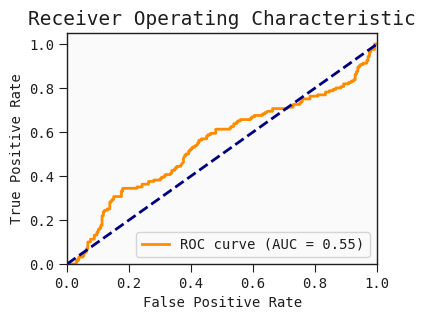

In [25]:
results_lr_demoM_auc_scores_all = extract_results(results_lr_demoM, 'auc_scores_all')
y_true_list_lr_demoM = extract_results(results_lr_demoM, 'y_true')
y_pred_prob_list_lr_demoM= extract_results(results_lr_demoM, 'y_pred_prob')
y_pred_list_lr_demoM= extract_results(results_lr_demoM, 'y_pred')
feature_selection_df_lr_demoM= extract_results(results_lr_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_demoM= extract_results(results_lr_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demoM}, Median AUC: {median_auc_lr_demoM}, IQR : {iqr_auc_lr_demoM}, IQ1-IQ3: {iqr13_auc_lr_demoM}") 
auc_plot(extract_results(results_lr_demoM, 'y_true'), extract_results(results_lr_demoM, 'y_pred_prob'))

## Demo +APOE4

In [26]:
demo_APOE4_lst =[ 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age','APOE4'] 
model_demo_APOE4_df = omics_demo_normalise_df_no_missing.copy()
model_demo_APOE4_df = model_demo_APOE4_df[demo_APOE4_lst+['label']]
model_demo_APOE4_df.columns

Index(['Demographic.Sex', 'Demographic.Years.of.Education.Exact', 'Age',
       'APOE4', 'label'],
      dtype='object')

In [27]:
model_demo_APOE4_df_M = model_demo_APOE4_df[model_demo_APOE4_df['Demographic.Sex']==1]
model_demo_APOE4_df_M = model_demo_APOE4_df_M.drop(['Demographic.Sex'], axis=1)
model_demo_APOE4_df_F = model_demo_APOE4_df[model_demo_APOE4_df['Demographic.Sex']==0]
model_demo_APOE4_df_F = model_demo_APOE4_df_F.drop(['Demographic.Sex'], axis=1)

#### LR-Full No feature selection

In [28]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4, overall_auc_lr_demo_APOE4, median_auc_lr_demo_APOE4, iqr_auc_lr_demo_APOE4, iqr13_auc_lr_demo_APOE4 = run_multiple_evaluations_parallel(model_demo_APOE4_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [29]:
results_lr_demo_APOE4_auc_scores_all = extract_results(results_lr_demo_APOE4, 'auc_scores_all')
evaluation_df2 = pd.DataFrame({'Model': "LR (Demographic+APOE4)", "AUC": results_lr_demo_APOE4_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df2], ignore_index=True)

Overall AUC: 0.4983844155844156, Median AUC: 0.5033766233766234, IQR : 0.03753246753246753, IQ1-IQ3: (0.4821428571428571, 0.5196753246753246)


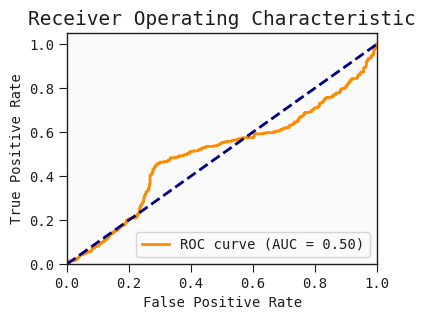

In [30]:
y_true_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_true')
y_pred_prob_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_pred_prob')
y_pred_list_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'y_pred')
feature_selection_df_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4 = extract_results(results_lr_demo_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4}, Median AUC: {median_auc_lr_demo_APOE4}, IQR : {iqr_auc_lr_demo_APOE4}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4}") 
auc_plot(extract_results(results_lr_demo_APOE4, 'y_true'), extract_results(results_lr_demo_APOE4, 'y_pred_prob'))

#### LR-Female No feature selection

In [31]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4F, overall_auc_lr_demo_APOE4F, median_auc_lr_demo_APOE4F, iqr_auc_lr_demo_APOE4F, iqr13_auc_lr_demo_APOE4F = run_multiple_evaluations_parallel(model_demo_APOE4_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5830984719864176, Median AUC: 0.5772495755517826, IQR : 0.03753246753246753, IQ1-IQ3: (0.5719439728353141, 0.6037775891341256)


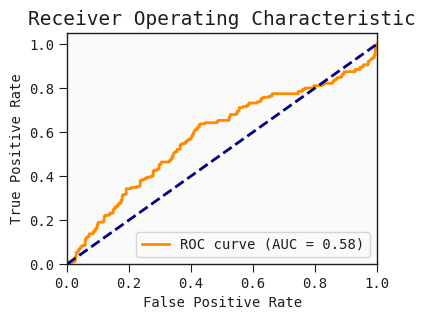

In [32]:
results_lr_demo_APOE4F_auc_scores_all = extract_results(results_lr_demo_APOE4F, 'auc_scores_all')
y_true_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_true')
y_pred_prob_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_pred_prob')
y_pred_list_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'y_pred')
feature_selection_df_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4F = extract_results(results_lr_demo_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4F}, Median AUC: {median_auc_lr_demo_APOE4F}, IQR : {iqr_auc_lr_demo_APOE4}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4F}") 
auc_plot(extract_results(results_lr_demo_APOE4F, 'y_true'), extract_results(results_lr_demo_APOE4F, 'y_pred_prob'))

#### LR-Male No feature selection

In [33]:
lr_param_grid = {
    'C': [1],  
    'penalty': [None],  
    'solver': ['saga']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
results_lr_demo_APOE4M, overall_auc_lr_demo_APOE4M, median_auc_lr_demo_APOE4M, iqr_auc_lr_demo_APOE4M, iqr13_auc_lr_demo_APOE4M = run_multiple_evaluations_parallel(model_demo_APOE4_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.5297135416666667, Median AUC: 0.5221354166666666, IQR : 0.06412760416666674, IQ1-IQ3: (0.49641927083333326, 0.560546875)


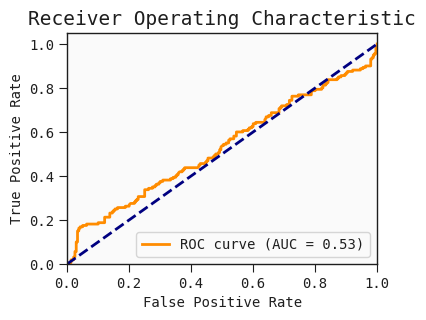

In [34]:
results_lr_demo_APOE4M_auc_scores_all = extract_results(results_lr_demo_APOE4M, 'auc_scores_all')
y_true_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_true')
y_pred_prob_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_pred_prob')
y_pred_list_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'y_pred')
feature_selection_df_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'feature_selection_df')
feature_sum_coef_df_lr_demo_APOE4M = extract_results(results_lr_demo_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_demo_APOE4M}, Median AUC: {median_auc_lr_demo_APOE4M}, IQR : {iqr_auc_lr_demo_APOE4M}, IQ1-IQ3: {iqr13_auc_lr_demo_APOE4M}") 
auc_plot(extract_results(results_lr_demo_APOE4M, 'y_true'), extract_results(results_lr_demo_APOE4M, 'y_pred_prob'))

## Omics

In [35]:
model_omics_df = omics_demo_normalise_df_no_missing.copy()
print(len(model_omics_df.columns))

1951


In [36]:
################ OMICS Only ####################
omics_only = ['Demographic.Sex']
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_lst = list((set(model_omics_df.columns.to_list()) - set(demo_lst_full)) | set(omics_only))
model_omics_df = omics_demo_normalise_df_no_missing.copy()
model_omics_df = model_omics_df[omics_lst]
print(len(model_omics_df.columns))
model_omics_df_M = model_omics_df[model_omics_df['Demographic.Sex']==1]
model_omics_df_M = model_omics_df_M.drop(['Demographic.Sex'], axis=1)
model_omics_df_F = model_omics_df[model_omics_df['Demographic.Sex']==0]
model_omics_df_F = model_omics_df_F.drop(['Demographic.Sex'], axis=1)
# model_omics_df = model_omics_df.drop(['Demographic.Sex'], axis=1)

1942


### Logistic Regression with Lasso


#### L1-Full No feature selection

In [37]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics, overall_auc_lr_omics, median_auc_lr_omics, iqr_auc_lr_omics, iqr13_auc_lr_omics = run_multiple_evaluations_parallel(model_omics_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [38]:
results_lr_omics_auc_scores_all = extract_results(results_lr_omics, 'auc_scores_all')
evaluation_df3 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics)", "AUC": results_lr_omics_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df3], ignore_index=True)

Overall AUC: 0.4747012987012987, Median AUC: 0.46818181818181814, IQR : 0.07337662337662337, IQ1-IQ3: (0.43428571428571433, 0.5076623376623377)


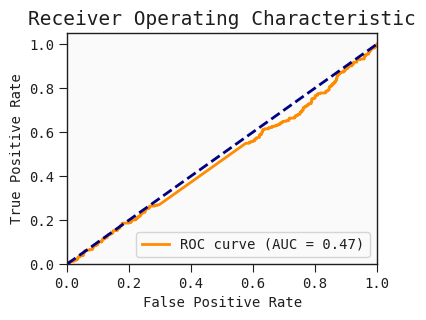

In [39]:
y_true_list_lr_omics = extract_results(results_lr_omics, 'y_true')
y_pred_prob_list_lr_omics= extract_results(results_lr_omics, 'y_pred_prob')
y_pred_list_lr_omics= extract_results(results_lr_omics, 'y_pred')
feature_selection_df_lr_omics= extract_results(results_lr_omics, 'feature_selection_df')
feature_sum_coef_df_lr_omics= extract_results(results_lr_omics, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics}, Median AUC: {median_auc_lr_omics}, IQR : {iqr_auc_lr_omics}, IQ1-IQ3: {iqr13_auc_lr_omics}") 
auc_plot(extract_results(results_lr_omics, 'y_true'), extract_results(results_lr_omics, 'y_pred_prob'))

#### L1-Female No feature selection

In [40]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omicsF, overall_auc_lr_omicsF, median_auc_lr_omicsF, iqr_auc_lr_omicsF, iqr13_auc_lr_omicsF = run_multiple_evaluations_parallel(model_omics_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [41]:
results_lr_omicsF_auc_scores_all = extract_results(results_lr_omicsF, 'auc_scores_all')
evaluation_df4 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics Female)", "AUC": results_lr_omicsF_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df4], ignore_index=True)

Overall AUC: 0.7721731748726657, Median AUC: 0.7784380305602716, IQR : 0.09040747028862484, IQ1-IQ3: (0.7355687606112054, 0.8259762308998302)


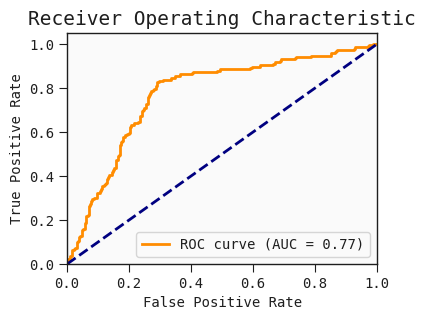

In [42]:
y_true_list_lr_omicsF = extract_results(results_lr_omicsF, 'y_true')
y_pred_prob_list_lr_omicsF= extract_results(results_lr_omicsF, 'y_pred_prob')
y_pred_list_lr_omicsF= extract_results(results_lr_omicsF, 'y_pred')
feature_selection_df_lr_omicsF= extract_results(results_lr_omicsF, 'feature_selection_df')
feature_sum_coef_df_lr_omicsF= extract_results(results_lr_omicsF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omicsF}, Median AUC: {median_auc_lr_omicsF}, IQR : {iqr_auc_lr_omicsF}, IQ1-IQ3: {iqr13_auc_lr_omicsF}") 
auc_plot(extract_results(results_lr_omicsF, 'y_true'), extract_results(results_lr_omicsF, 'y_pred_prob'))

#### L1-Male No feature selection

In [45]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omicsM, overall_auc_lr_omicsM, median_auc_lr_omicsM, iqr_auc_lr_omicsM, iqr13_auc_lr_omicsM = run_multiple_evaluations_parallel(model_omics_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [46]:
results_lr_omicsM_auc_scores_all = extract_results(results_lr_omicsM, 'auc_scores_all')
evaluation_df5 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics Male)", "AUC": results_lr_omicsM_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df5], ignore_index=True)

Overall AUC: 0.8241276041666666, Median AUC: 0.81640625, IQR : 0.05989583333333337, IQ1-IQ3: (0.8053385416666666, 0.865234375)


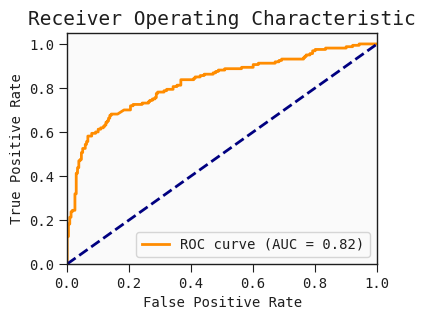

In [47]:
y_true_list_lr_omicsM = extract_results(results_lr_omicsM, 'y_true')
y_pred_prob_list_lr_omicsM= extract_results(results_lr_omicsM, 'y_pred_prob')
y_pred_list_lr_omicsM= extract_results(results_lr_omicsM, 'y_pred')
feature_selection_df_lr_omicsM= extract_results(results_lr_omicsM, 'feature_selection_df')
feature_sum_coef_df_lr_omicsM= extract_results(results_lr_omicsM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omicsM}, Median AUC: {median_auc_lr_omicsM}, IQR : {iqr_auc_lr_omicsM}, IQ1-IQ3: {iqr13_auc_lr_omicsM}") 
auc_plot(extract_results(results_lr_omicsM, 'y_true'), extract_results(results_lr_omicsM, 'y_pred_prob'))

## Omics + APOE4

In [50]:
################ OMICS + APOE4 ####################
model_omics_APOE4_df = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_APOE4 = ['Demographic.Sex','APOE4']
omics_APOE4_lst = list((set(model_omics_APOE4_df.columns.to_list()) - set(demo_lst_full)) | set(omics_APOE4))
model_omics_df_APOE4 = model_omics_APOE4_df[omics_APOE4_lst]
print(len(model_omics_df_APOE4.columns))
model_omics_df_M_APOE4 = model_omics_df_APOE4[model_omics_df_APOE4['Demographic.Sex']==1]
model_omics_df_M_APOE4 = model_omics_df_M_APOE4.drop(['Demographic.Sex'], axis=1)
model_omics_df_F_APOE4 = model_omics_df_APOE4[model_omics_df_APOE4['Demographic.Sex']==0]
model_omics_df_F_APOE4 = model_omics_df_F_APOE4.drop(['Demographic.Sex'], axis=1)

1943


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [51]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4, overall_auc_lr_omics_APOE4, median_auc_lr_omics_APOE4, iqr_auc_lr_omics_APOE4, iqr13_auc_lr_omics_APOE4 = run_multiple_evaluations_parallel(model_omics_df_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.4808233766233766, Median AUC: 0.47155844155844157, IQR : 0.032532467532467524, IQ1-IQ3: (0.45675324675324674, 0.48928571428571427)


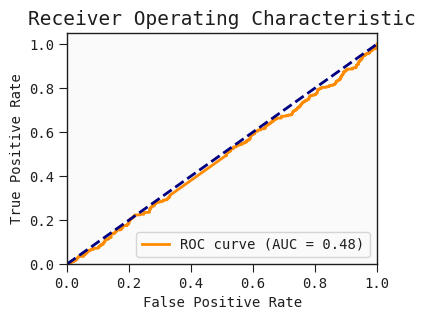

In [52]:
results_lr_omics_APOE4_auc_scores_all = extract_results(results_lr_omics_APOE4, 'auc_scores_all')
y_true_list_lr_omics_APOE4 = extract_results(results_lr_omics_APOE4, 'y_true')
y_pred_prob_list_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'y_pred_prob')
y_pred_list_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'y_pred')
feature_selection_df_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4= extract_results(results_lr_omics_APOE4, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4}, Median AUC: {median_auc_lr_omics_APOE4}, IQR : {iqr_auc_lr_omics_APOE4}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4}") 
auc_plot(extract_results(results_lr_omics_APOE4, 'y_true'), extract_results(results_lr_omics_APOE4, 'y_pred_prob'))

#### L1-Female No feature selection

In [53]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4F, overall_auc_lr_omics_APOE4F, median_auc_lr_omics_APOE4F, iqr_auc_lr_omics_APOE4F, iqr13_auc_lr_omics_APOE4F = run_multiple_evaluations_parallel(model_omics_df_F_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.7720203735144312, Median AUC: 0.7809847198641766, IQR : 0.029286926994906648, IQ1-IQ3: (0.7597623089983022, 0.7890492359932089)


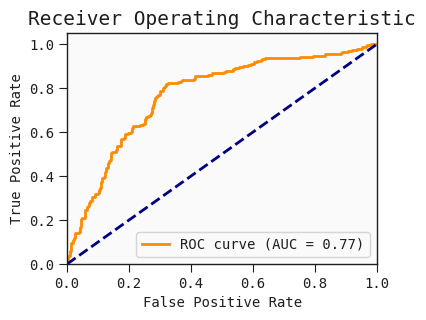

In [54]:
results_lr_omics_APOE4F_auc_scores_all = extract_results(results_lr_omics_APOE4F, 'auc_scores_all')
y_true_list_lr_omics_APOE4F = extract_results(results_lr_omics_APOE4F, 'y_true')
y_pred_prob_list_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'y_pred_prob')
y_pred_list_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'y_pred')
feature_selection_df_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4F= extract_results(results_lr_omics_APOE4F, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4F}, Median AUC: {median_auc_lr_omics_APOE4F}, IQR : {iqr_auc_lr_omics_APOE4F}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4F}") 
auc_plot(extract_results(results_lr_omics_APOE4F, 'y_true'), extract_results(results_lr_omics_APOE4F, 'y_pred_prob'))

#### L1-Male No feature selection

In [55]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4M, overall_auc_lr_omics_APOE4M, median_auc_lr_omics_APOE4M, iqr_auc_lr_omics_APOE4M, iqr13_auc_lr_omics_APOE4M = run_multiple_evaluations_parallel(model_omics_df_M_APOE4, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.8277213541666666, Median AUC: 0.8463541666666667, IQR : 0.07259114583333315, IQ1-IQ3: (0.8004557291666667, 0.8730468749999999)


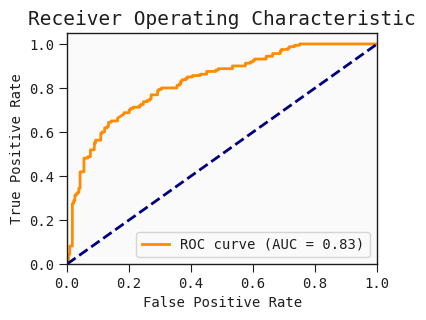

In [56]:
results_lr_omics_APOE4M_auc_scores_all = extract_results(results_lr_omics_APOE4M, 'auc_scores_all')
y_true_list_lr_omics_APOE4M = extract_results(results_lr_omics_APOE4M, 'y_true')
y_pred_prob_list_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'y_pred_prob')
y_pred_list_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'y_pred')
feature_selection_df_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4M= extract_results(results_lr_omics_APOE4M, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4M}, Median AUC: {median_auc_lr_omics_APOE4M}, IQR : {iqr_auc_lr_omics_APOE4M}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4M}") 
auc_plot(extract_results(results_lr_omics_APOE4M, 'y_true'), extract_results(results_lr_omics_APOE4M, 'y_pred_prob'))

## Omics+Demo

In [57]:
################ OMICS + Demo ####################
model_omics_df = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_demo = ['Demographic.Sex','Demographic.Years.of.Education.Exact','Age']
omics_demo_lst = list((set(model_omics_df.columns.to_list()) - set(demo_lst_full)) | set(omics_demo))
model_omics_df_demo = model_omics_df[omics_demo_lst]
print(len(model_omics_df_demo.columns))
model_omics_df_M_demo = model_omics_df_demo[model_omics_df_demo['Demographic.Sex']==1]
model_omics_df_M_demo = model_omics_df_M_demo.drop(['Demographic.Sex'], axis=1)
model_omics_df_F_demo = model_omics_df_demo[model_omics_df_demo['Demographic.Sex']==0]
model_omics_df_F_demo = model_omics_df_F_demo.drop(['Demographic.Sex'], axis=1)
# model_omics_df_demo = model_omics_df_demo.drop(['Demographic.Sex'], axis=1)

1944


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [58]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demo, overall_auc_lr_omics_demo, median_auc_lr_omics_demo, iqr_auc_lr_omics_demo, iqr13_auc_lr_omics_demo = run_multiple_evaluations_parallel(model_omics_df_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.4739324675324676, Median AUC: 0.46350649350649353, IQR : 0.0755194805194806, IQ1-IQ3: (0.44337662337662337, 0.518896103896104)


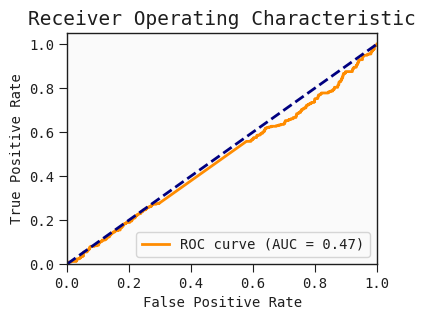

In [59]:
y_true_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_true')
y_pred_prob_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_pred_prob')
y_pred_list_lr_omics_demo = extract_results(results_lr_omics_demo, 'y_pred')
feature_selection_df_lr_omics_demo = extract_results(results_lr_omics_demo, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demo = extract_results(results_lr_omics_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demo}, Median AUC: {median_auc_lr_omics_demo}, IQR : {iqr_auc_lr_omics_demo}, IQ1-IQ3: {iqr13_auc_lr_omics_demo}") 
auc_plot(extract_results(results_lr_omics_demo, 'y_true'), extract_results(results_lr_omics_demo, 'y_pred_prob'))

#### L1-Female No feature selection

In [60]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demoF, overall_auc_lr_omics_demoF, median_auc_lr_omics_demoF, iqr_auc_lr_omics_demoF, iqr13_auc_lr_omics_demoF = run_multiple_evaluations_parallel(model_omics_df_F_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.774346349745331, Median AUC: 0.7767402376910018, IQR : 0.08191850594227501, IQ1-IQ3: (0.7440577249575552, 0.8259762308998302)


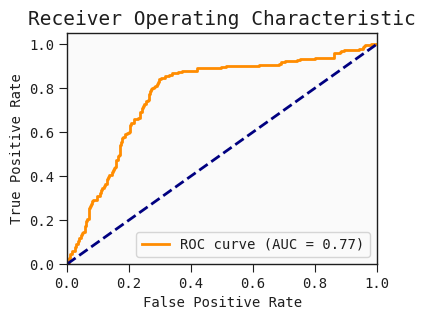

In [61]:
y_true_list_lr_omics_demoF = extract_results(results_lr_omics_demoF, 'y_true')
y_pred_prob_list_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'y_pred_prob')
y_pred_list_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'y_pred')
feature_selection_df_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demoF= extract_results(results_lr_omics_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demoF}, Median AUC: {median_auc_lr_omics_demoF}, IQR : {iqr_auc_lr_omics_demoF}, IQ1-IQ3: {iqr13_auc_lr_omics_demoF}") 
auc_plot(extract_results(results_lr_omics_demoF, 'y_true'), extract_results(results_lr_omics_demoF, 'y_pred_prob'))

#### L1-Male No feature selection

In [62]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_demoM, overall_auc_lr_omics_demoM, median_auc_lr_omics_demoM, iqr_auc_lr_omics_demoM, iqr13_auc_lr_omics_demoM = run_multiple_evaluations_parallel(model_omics_df_M_demo, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.8281901041666666, Median AUC: 0.8255208333333333, IQR : 0.06184895833333348, IQ1-IQ3: (0.7942708333333333, 0.8561197916666667)


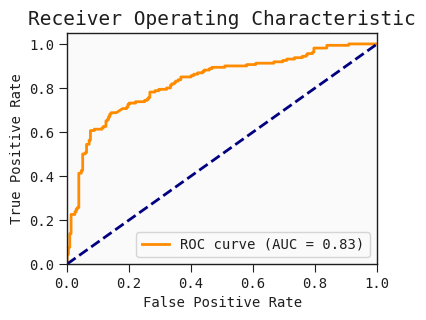

In [63]:
y_true_list_lr_omics_demoM = extract_results(results_lr_omics_demoM, 'y_true')
y_pred_prob_list_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'y_pred_prob')
y_pred_list_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'y_pred')
feature_selection_df_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_omics_demoM= extract_results(results_lr_omics_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_demoM}, Median AUC: {median_auc_lr_omics_demoM}, IQR : {iqr_auc_lr_omics_demoM}, IQ1-IQ3: {iqr13_auc_lr_omics_demoM}") 
auc_plot(extract_results(results_lr_omics_demoM, 'y_true'), extract_results(results_lr_omics_demoM, 'y_pred_prob'))

## Omics+APOE4+Demo

In [64]:
################ OMICS + APOE4 + Demo ####################
model_omics_APOE4_demo_df_full = omics_demo_normalise_df_no_missing.copy()
demo_lst_full=['APOE4','Demographic.Sex', 'Vital.Signs.Body.Mass.Index', 'Demographic.GDS', 'Demographic.Years.of.Education.Exact','Age']+one_hot_encoded_handedness_names
omics_APOE4_demo = ['APOE4', 'Demographic.Sex', 'Demographic.Years.of.Education.Exact','Age']
omics_APOE4_demo_lst = list((set(model_omics_APOE4_demo_df_full.columns.to_list()) - set(demo_lst_full)) | set(omics_APOE4_demo))
print(len(omics_APOE4_demo_lst))
model_omics_APOE4_demo_df = model_omics_APOE4_demo_df_full[omics_APOE4_demo_lst]
model_omics_APOE4_demo_df_M = model_omics_APOE4_demo_df[model_omics_APOE4_demo_df['Demographic.Sex']==1]
model_omics_APOE4_demo_df_M = model_omics_APOE4_demo_df_M.drop(['Demographic.Sex'], axis=1)
model_omics_APOE4_demo_df_F = model_omics_APOE4_demo_df[model_omics_APOE4_demo_df['Demographic.Sex']==0]
model_omics_APOE4_demo_df_F = model_omics_APOE4_demo_df_F.drop(['Demographic.Sex'], axis=1)
# model_omics_APOE4_demo_df = model_omics_APOE4_demo_df.drop(['Demographic.Sex'], axis=1)

1945


### Logistic Regression with Lasso

#### L1-Full No feature selection

In [65]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demo, overall_auc_lr_omics_APOE4_demo, median_auc_lr_omics_APOE4_demo, iqr_auc_lr_omics_APOE4_demo, iqr13_auc_lr_omics_APOE4_demo = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

Overall AUC: 0.4750155844155844, Median AUC: 0.46792207792207796, IQR : 0.03688311688311685, IQ1-IQ3: (0.4430519480519481, 0.47993506493506494)


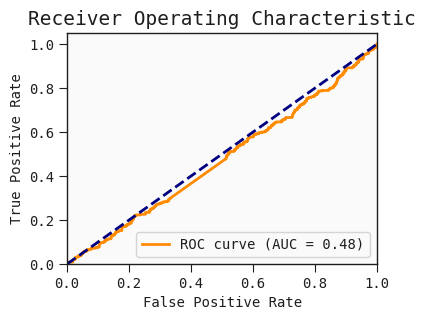

In [67]:
y_true_list_lr_omics_APOE4_demo = extract_results(results_lr_omics_APOE4_demo, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'y_pred')
feature_selection_df_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demo= extract_results(results_lr_omics_APOE4_demo, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demo}, Median AUC: {median_auc_lr_omics_APOE4_demo}, IQR : {iqr_auc_lr_omics_APOE4_demo}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demo}") 
auc_plot(extract_results(results_lr_omics_APOE4_demo, 'y_true'), extract_results(results_lr_omics_APOE4_demo, 'y_pred_prob'))

#### L1-Female No feature selection

In [68]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demoF, overall_auc_lr_omics_APOE4_demoF, median_auc_lr_omics_APOE4_demoF, iqr_auc_lr_omics_APOE4_demoF, iqr13_auc_lr_omics_APOE4_demoF = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_F, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [69]:
results_lr_omics_APOE4_demoF_auc_scores_all = extract_results(results_lr_omics_APOE4_demoF, 'auc_scores_all')
evaluation_df6 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics+APOE4+Demographic Female)", "AUC": results_lr_omics_APOE4_demoF_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df6], ignore_index=True)

Overall AUC: 0.7713582342954161, Median AUC: 0.7775891341256367, IQR : 0.029286926994906648, IQ1-IQ3: (0.7597623089983022, 0.7890492359932089)


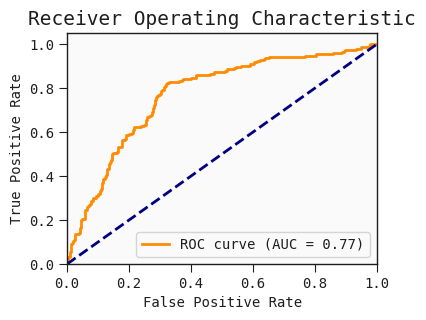

In [70]:
y_true_list_lr_omics_APOE4_demoF = extract_results(results_lr_omics_APOE4_demoF, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'y_pred')
feature_selection_df_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demoF= extract_results(results_lr_omics_APOE4_demoF, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demoF}, Median AUC: {median_auc_lr_omics_APOE4_demoF}, IQR : {iqr_auc_lr_omics_APOE4_demoF}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demoF}") 
auc_plot(extract_results(results_lr_omics_APOE4_demoF, 'y_true'), extract_results(results_lr_omics_APOE4_demoF, 'y_pred_prob'))

In [71]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
y_true_list_lr_omics_APOE4_demoF_single, y_pred_prob_list_lr_omics_APOE4_demoF_single, y_pred_list_lr_omics_APOE4_demoF_single, feature_selection_df_lr_omics_APOE4_demoF_single=evaluate_full_dataset(model_omics_APOE4_demo_df_F, 'logistic_regression', lr_param_combinations, feature_selection_method=None, num_features=None)

In [72]:
feature_selection_df_lr_omics_APOE4_demoF_single['Feature'] = feature_selection_df_lr_omics_APOE4_demoF_single['Feature'].map(mapping_dict)

In [73]:
print(feature_selection_df_lr_omics_APOE4_demoF_single.shape)

(40, 2)


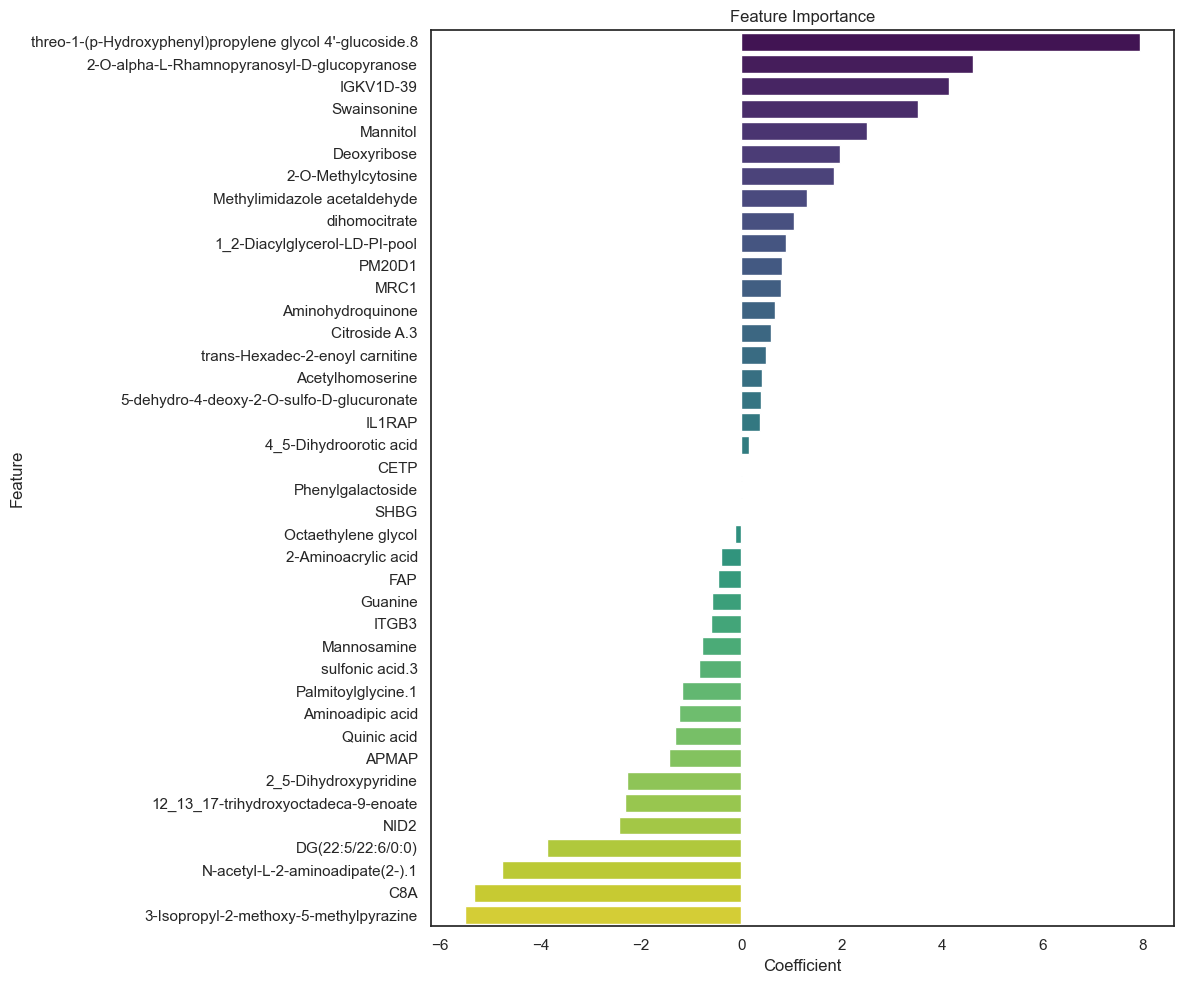

In [98]:
# Set the plot size
plt.figure(figsize=(12, 10))

sns.barplot(
    x='CoefficientSum', 
    y='Feature', 
    data=feature_selection_df_lr_omics_APOE4_demoF_single, 
    palette='viridis'
)

plt.title('Feature Importance')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.yticks(fontsize=11)
plt.tight_layout()
plt.savefig("../plots/single_coeff_Female.pdf", format='pdf')
plt.show()

In [75]:
feature_selection_df_lr_omics_APOE4_demoF['Feature'] = feature_selection_df_lr_omics_APOE4_demoF['Feature'].map(mapping_dict)
feature_sum_coef_df_lr_omics_APOE4_demoF['Feature'] = feature_sum_coef_df_lr_omics_APOE4_demoF['Feature'].map(mapping_dict)

In [76]:
feature_selection_df_lr_omics_APOE4_demoF = feature_selection_df_lr_omics_APOE4_demoF.sort_values(by='Total Count', ascending=False)
feature_selection_df_lr_omics_APOE4_demoF.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_selected.csv", index=False)
feature_sum_coef_df_lr_omics_APOE4_demoF = feature_sum_coef_df_lr_omics_APOE4_demoF.sort_values(by='Coefficient Sum', ascending=False)
feature_sum_coef_df_lr_omics_APOE4_demoF.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_sum_coefficient.csv", index=False)
feature_selection_df_lr_omics_APOE4_demoF_single = feature_selection_df_lr_omics_APOE4_demoF_single.sort_values(by='CoefficientSum', ascending=False)
feature_selection_df_lr_omics_APOE4_demoF_single.to_csv("../results/Lasso_female_omics_APOE_DEMO_feature_single_coefficient.csv", index=False)

#### L1-Male No feature selection

In [77]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))

results_lr_omics_APOE4_demoM, overall_auc_lr_omics_APOE4_demoM, median_auc_lr_omics_APOE4_demoM, iqr_auc_lr_omics_APOE4_demoM, iqr13_auc_lr_omics_APOE4_demoM = run_multiple_evaluations_parallel(model_omics_APOE4_demo_df_M, 'logistic_regression', lr_param_combinations, n_runs=10, global_seed=42) 

In [78]:
results_lr_omics_APOE4_demoM_auc_scores_all = extract_results(results_lr_omics_APOE4_demoM, 'auc_scores_all')
evaluation_df7 = pd.DataFrame({'Model': "LR with Lasso (Multi-omics+APOE4+Demographic Male)", "AUC": results_lr_omics_APOE4_demoM_auc_scores_all})
overall_evaluation_df = pd.concat([overall_evaluation_df,evaluation_df7], ignore_index=True)

Overall AUC: 0.8340494791666667, Median AUC: 0.8619791666666666, IQR : 0.06412760416666674, IQ1-IQ3: (0.8076171875, 0.8717447916666667)


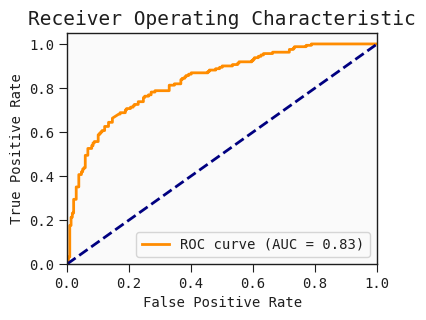

In [79]:
y_true_list_lr_omics_APOE4_demoM = extract_results(results_lr_omics_APOE4_demoM, 'y_true')
y_pred_prob_list_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'y_pred_prob')
y_pred_list_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'y_pred')
feature_selection_df_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'feature_selection_df')
feature_sum_coef_df_lr_omics_APOE4_demoM= extract_results(results_lr_omics_APOE4_demoM, 'feature_coef_df')
print(f"Overall AUC: {overall_auc_lr_omics_APOE4_demoM}, Median AUC: {median_auc_lr_omics_APOE4_demoM}, IQR : {iqr_auc_lr_omics_APOE4_demoM}, IQ1-IQ3: {iqr13_auc_lr_omics_APOE4_demoM}") 
auc_plot(extract_results(results_lr_omics_APOE4_demoM, 'y_true'), extract_results(results_lr_omics_APOE4_demoM, 'y_pred_prob'))

In [80]:
lr_param_grid = {
    'C': [ 0.01, 0.1, 0.5, 1, 5, 10, 100],  
    'penalty': ['l1'],  
    'solver': ['saga','liblinear']  
}
lr_param_combinations = list(itertools.product(lr_param_grid['C'], lr_param_grid['penalty'], lr_param_grid['solver']))
y_true_list_lr_omics_APOE4_demoM_single, y_pred_prob_list_lr_omics_APOE4_demoM_single, y_pred_list_lr_omics_APOE4_demoM_single, feature_selection_df_lr_omics_APOE4_demoM_single=evaluate_full_dataset(model_omics_APOE4_demo_df_M, 'logistic_regression', lr_param_combinations, feature_selection_method=None, num_features=None)

In [81]:
feature_selection_df_lr_omics_APOE4_demoM_single['Feature'] = feature_selection_df_lr_omics_APOE4_demoM_single['Feature'].map(mapping_dict)

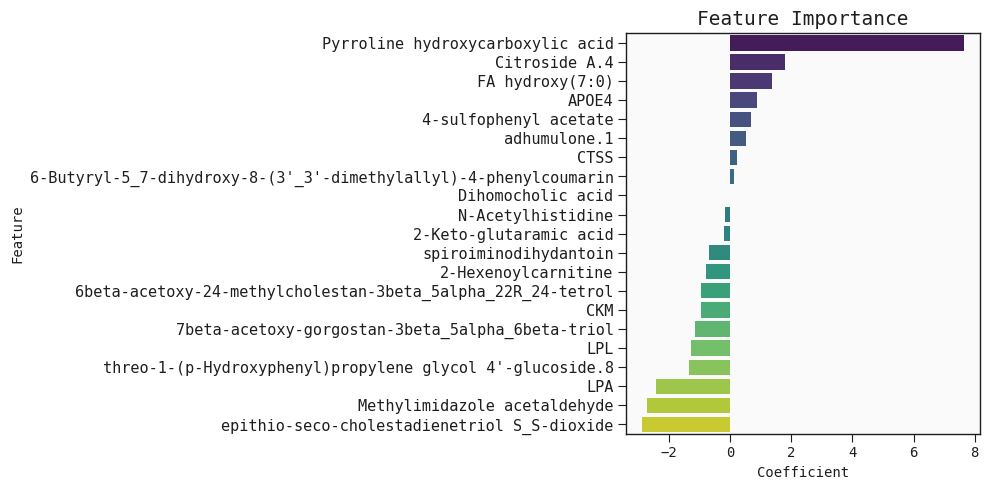

In [82]:
# Set the plot size
plt.figure(figsize=(10, 5))

sns.barplot(
    x='CoefficientSum', 
    y='Feature', 
    data=feature_selection_df_lr_omics_APOE4_demoM_single, 
    palette='viridis'
)

# Add title and labels
plt.title('Feature Importance')
plt.xlabel('Coefficient')
plt.ylabel('Feature')
plt.yticks(fontsize=11)

# Adjust layout
plt.tight_layout()
plt.savefig("../plots/single_coeff_Male.pdf", format='pdf')
# Display the plot
plt.show()

In [83]:
feature_selection_df_lr_omics_APOE4_demoM['Feature'] = feature_selection_df_lr_omics_APOE4_demoM['Feature'].map(mapping_dict)
feature_sum_coef_df_lr_omics_APOE4_demoM['Feature'] = feature_sum_coef_df_lr_omics_APOE4_demoM['Feature'].map(mapping_dict)

In [84]:
feature_selection_df_lr_omics_APOE4_demoM = feature_selection_df_lr_omics_APOE4_demoM.sort_values(by='Total Count', ascending=False)
feature_selection_df_lr_omics_APOE4_demoM.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_selected.csv", index=False)
feature_sum_coef_df_lr_omics_APOE4_demoM = feature_sum_coef_df_lr_omics_APOE4_demoM.sort_values(by='Coefficient Sum', ascending=False)
feature_sum_coef_df_lr_omics_APOE4_demoM.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_sum_coefficient.csv", index=False)
feature_selection_df_lr_omics_APOE4_demoM_single = feature_selection_df_lr_omics_APOE4_demoM_single.sort_values(by='CoefficientSum', ascending=False)
feature_selection_df_lr_omics_APOE4_demoM_single.to_csv("../results/Lasso_male_omics_APOE_DEMO_feature_single_coefficient.csv", index=False)

# Results

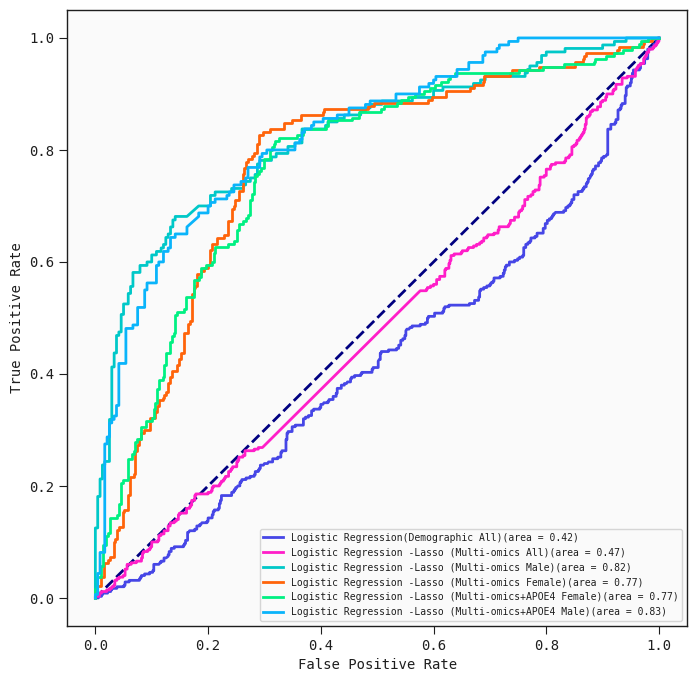

In [85]:
models = [
    {'y_true':  y_true_list_lr_demo, 'y_pred': y_pred_list_lr_demo, 'prob': y_pred_prob_list_lr_demo, 'label': 'Logistic Regression(Demographic All)'},
    {'y_true':  y_true_list_lr_omics, 'y_pred': y_pred_list_lr_omics, 'prob': y_pred_prob_list_lr_omics, 'label': 'Logistic Regression -Lasso (Multi-omics All)'},
    {'y_true':  y_true_list_lr_omicsM, 'y_pred': y_pred_list_lr_omicsM, 'prob': y_pred_prob_list_lr_omicsM, 'label': 'Logistic Regression -Lasso (Multi-omics Male)'},
    {'y_true':  y_true_list_lr_omicsF, 'y_pred': y_pred_list_lr_omicsF, 'prob': y_pred_prob_list_lr_omicsF, 'label': 'Logistic Regression -Lasso (Multi-omics Female)'},
    # {'y_true':  y_true_list_ql_omics, 'y_pred': y_pred_list_ql_omics, 'prob': y_pred_prob_list_ql_omics, 'label': 'QLattice (Multi-omics All)'},
    {'y_true':  y_true_list_lr_omics_APOE4F, 'y_pred': y_pred_list_lr_omics_APOE4F, 'prob': y_pred_prob_list_lr_omics_APOE4F, 'label': 'Logistic Regression -Lasso (Multi-omics+APOE4 Female)'},
    {'y_true':  y_true_list_lr_omics_APOE4M, 'y_pred': y_pred_list_lr_omics_APOE4M, 'prob': y_pred_prob_list_lr_omics_APOE4M, 'label': 'Logistic Regression -Lasso (Multi-omics+APOE4 Male)'}
        ]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
for i, model in enumerate(models):
    fpr, tpr, _ = roc_curve(model['y_true'], model['prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{model['label']}(area = {roc_auc:.2f})")
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.legend(loc='lower right', fontsize=7)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.show()

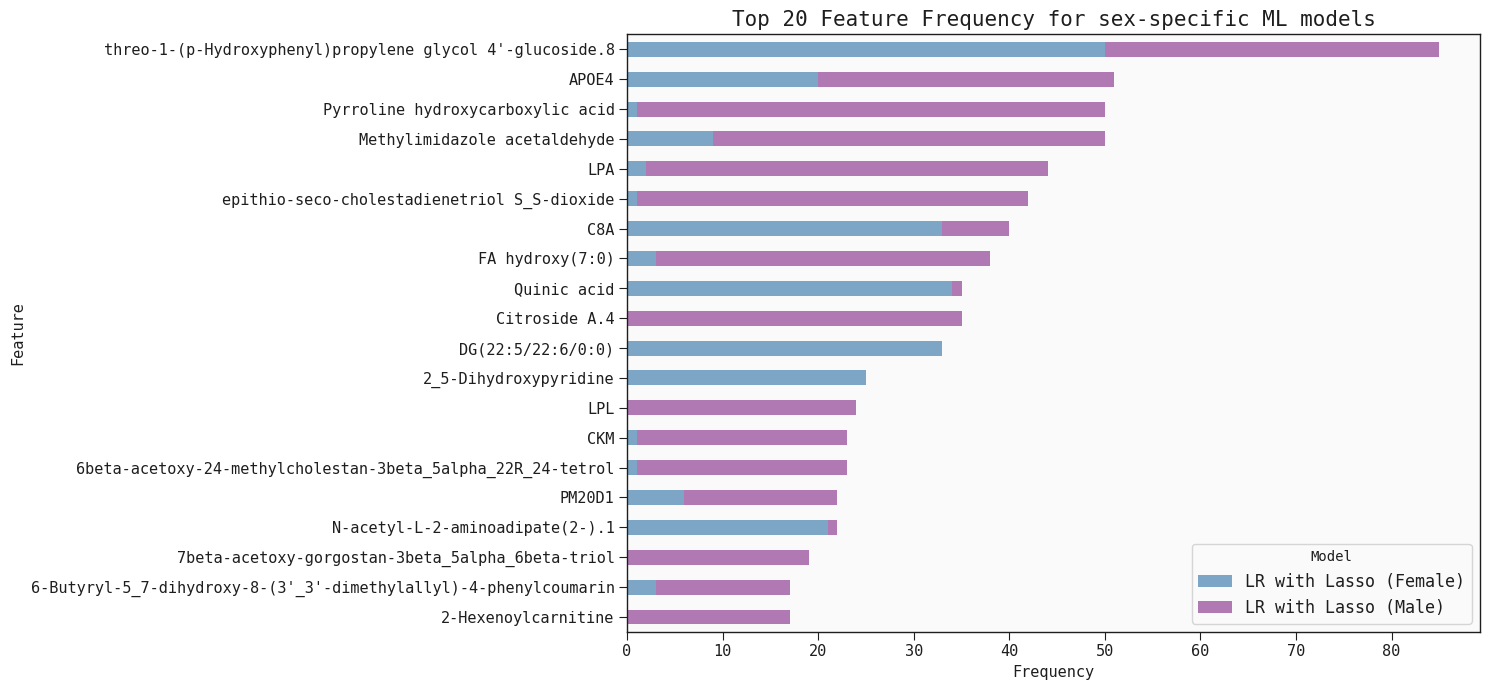

In [86]:
from matplotlib.ticker import MaxNLocator
def plot_stacked_feature_importance(dfs, labels, colors, file_path_name):
    merged_df = dfs[0].rename(columns={'Count': labels[0]}).set_index('Feature')
    for df, label in zip(dfs[1:], labels[1:]):
        merged_df = merged_df.merge(df.rename(columns={'Count': label}).set_index('Feature'), 
                                    left_index=True, right_index=True, how='outer')
    
    merged_df.fillna(0, inplace=True)
    
    # Sum up counts across all models to determine the top features
    merged_df['Total'] = merged_df.sum(axis=1)
    top_features_df = merged_df.sort_values(by='Total', ascending=False).head(20).drop(columns='Total')
    
    # Plotting

    ax = top_features_df.plot(kind='barh', stacked=True, figsize=(15, 7), color=colors)
    plt.title('Top 20 Feature Frequency for sex-specific ML models', fontsize=15)
    plt.xlabel('Frequency', fontsize=11)
    plt.ylabel('Feature', fontsize=11)
    plt.legend(title='Model', labels=labels, fontsize=12)
    plt.xticks(fontsize=11)
    plt.yticks(fontsize=11)
    plt.gca().invert_yaxis() 
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    plt.savefig(file_path_name, format='pdf')
    plt.show()


plot_stacked_feature_importance([feature_selection_df_lr_omics_APOE4_demoF, feature_selection_df_lr_omics_APOE4_demoM], ['LR with Lasso (Female)', 'LR with Lasso (Male)' ],['#7DA6C6', '#B179B4'], '../plots/Top_20_features.pdf')

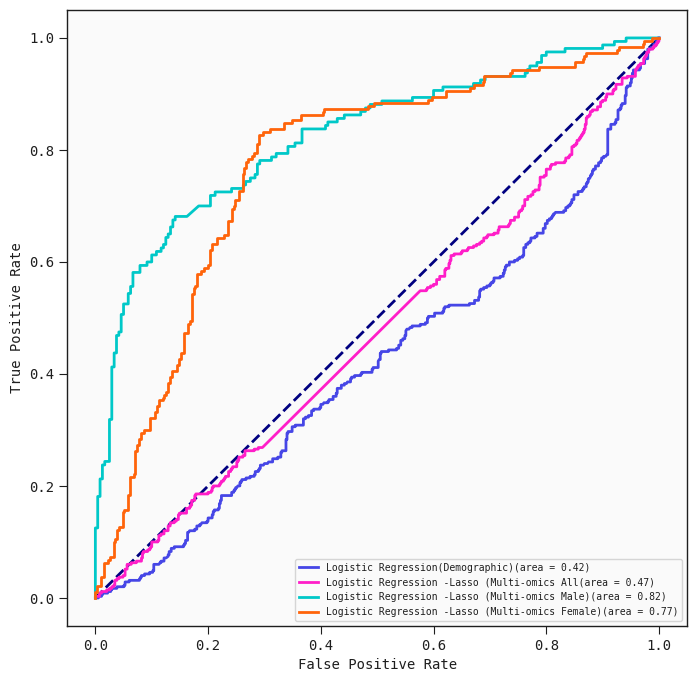

In [87]:
models = [
    {'y_true':  y_true_list_lr_demo, 'y_pred': y_pred_list_lr_demo, 'prob': y_pred_prob_list_lr_demo, 'label': 'Logistic Regression(Demographic)'},
    {'y_true':  y_true_list_lr_omics, 'y_pred': y_pred_list_lr_omics, 'prob': y_pred_prob_list_lr_omics, 'label': 'Logistic Regression -Lasso (Multi-omics All'},
    {'y_true':  y_true_list_lr_omicsM, 'y_pred': y_pred_list_lr_omicsM, 'prob': y_pred_prob_list_lr_omicsM, 'label': 'Logistic Regression -Lasso (Multi-omics Male)'},
    {'y_true':  y_true_list_lr_omicsF, 'y_pred': y_pred_list_lr_omicsF, 'prob': y_pred_prob_list_lr_omicsF, 'label': 'Logistic Regression -Lasso (Multi-omics Female)'},
    # {'y_true':  y_true_list_ql_omics, 'y_pred': y_pred_list_ql_omics, 'prob': y_pred_prob_list_ql_omics, 'label': 'QLattice (Multi-omics All)'},
    ]

plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
for i, model in enumerate(models):
    fpr, tpr, _ = roc_curve(model['y_true'], model['prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{model['label']}(area = {roc_auc:.2f})")
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.legend(loc='lower right', fontsize=7)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.savefig("../plots/AUC_performance1.pdf", format='pdf')
plt.show()

In [88]:
overall_evaluation_df['Model'].unique()

array(['LR (Demographic)', 'LR (Demographic+APOE4)',
       'LR with Lasso (Multi-omics)',
       'LR with Lasso (Multi-omics Female)',
       'LR with Lasso (Multi-omics Male)',
       'LR with Lasso (Multi-omics+APOE4+Demographic Female)',
       'LR with Lasso (Multi-omics+APOE4+Demographic Male)'], dtype=object)

(<Axes: xlabel='Model', ylabel='AUC'>,
  <statannotations.Annotation.Annotation at 0x16d189610>])

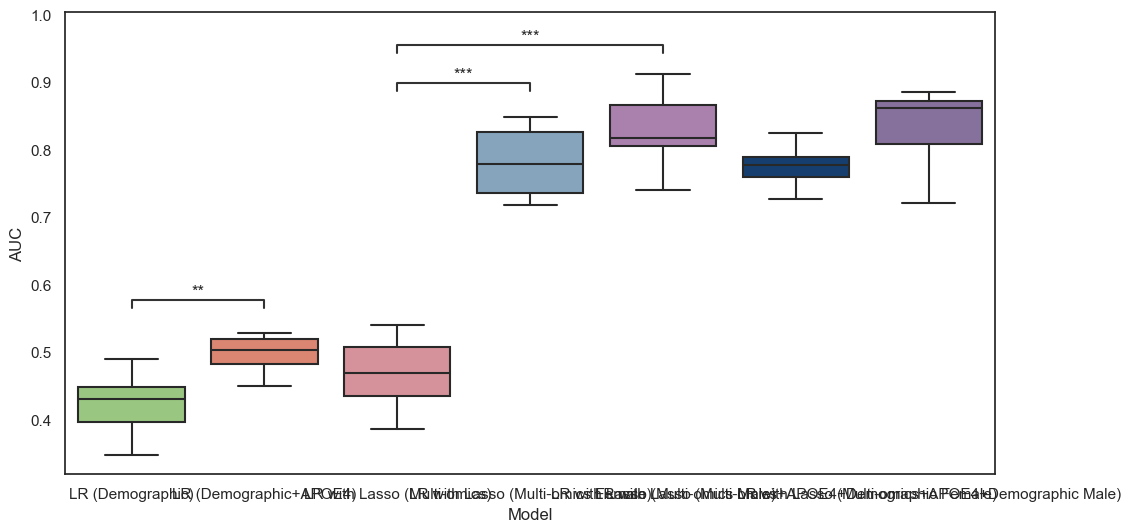

In [96]:
from statannotations.Annotator import Annotator
sns.set(style="white")
palette = {
    "LR (Demographic)": "#96D274",
    "LR (Demographic+APOE4)": "#ED7B61",
    "LR with Lasso (Multi-omics)": "#E18791",
    "LR with Lasso (Multi-omics Female)": '#7DA6C6',
    "LR with Lasso (Multi-omics Male)": '#B179B4',
    'LR with Lasso (Multi-omics+APOE4+Demographic Female)': "#073E7F",
    'LR with Lasso (Multi-omics+APOE4+Demographic Male)': "#866AA3",
}

fig_args = {'x': "Model",
            'y': "AUC",
            'data': overall_evaluation_df,
            'order': ["LR (Demographic)", "LR (Demographic+APOE4)", "LR with Lasso (Multi-omics)", 
                        "LR with Lasso (Multi-omics Female)", "LR with Lasso (Multi-omics Male)",
                        'LR with Lasso (Multi-omics+APOE4+Demographic Female)', 'LR with Lasso (Multi-omics+APOE4+Demographic Male)'],
            'palette': palette}
fig, ax = plt.subplots(1,1, figsize=(12,6))

sns.boxplot(ax=ax, **fig_args)
configuration = {'test':'Mann-Whitney',
                 'comparisons_correction':None,
                 'text_format':'star',
                 'loc': 'inside', 
                 'verbose': 0,
                 'fontsize': 12}
annotator = Annotator(ax=ax, pairs=[("LR (Demographic)", "LR (Demographic+APOE4)"),
                                    # ("LR (Demographic)", "LR with Lasso (Multi-omics)"),
                              ("LR with Lasso (Multi-omics)", "LR with Lasso (Multi-omics Female)"), 
                              ("LR with Lasso (Multi-omics)", "LR with Lasso (Multi-omics Male)"),
                            #   ("LR with Lasso (Multi-omics Female)", "LR with Lasso (Multi-omics+APOE4+Demographic Female)"),
                            #   ("LR with Lasso (Multi-omics Male)", "LR with Lasso (Multi-omics+APOE4+Demographic Male)")
                              ],
                      **fig_args, plot='boxplot')
annotator.configure(**configuration).apply_test().annotate()

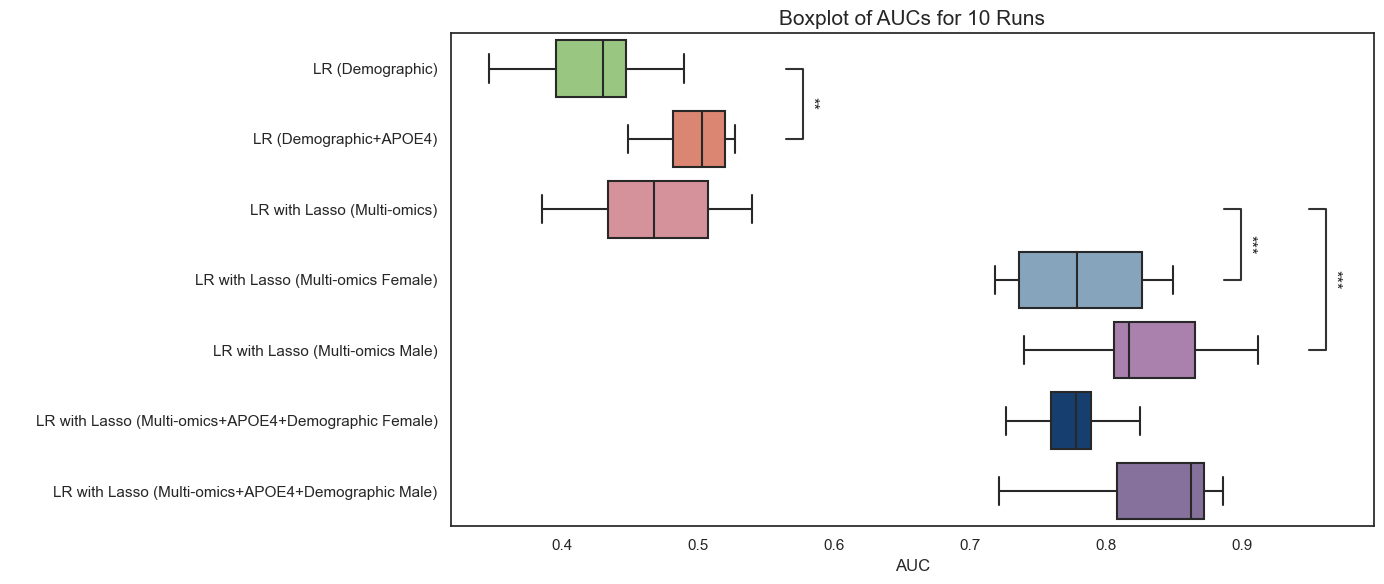

In [97]:
fig, ax = plt.subplots(1,1, figsize=(14,6))
fig_args_horiz = {
    **fig_args,
    'y': "Model",
    'x': "AUC"
}
# ax.set_xscale('log')
sns.boxplot(ax=ax, orient='h', **fig_args_horiz)
annotator.new_plot(ax, plot='swarmplot', orient='h', **fig_args_horiz)
annotator.apply_and_annotate()
ax.set_xlabel('AUC', fontsize=12)  # X-axis label font size
ax.set_ylabel(' ', fontsize=16) 
plt.title('Boxplot of AUCs for 10 Runs', fontsize=15)
plt.tight_layout()
plt.savefig("../plots/box_AUC.pdf", format='pdf')

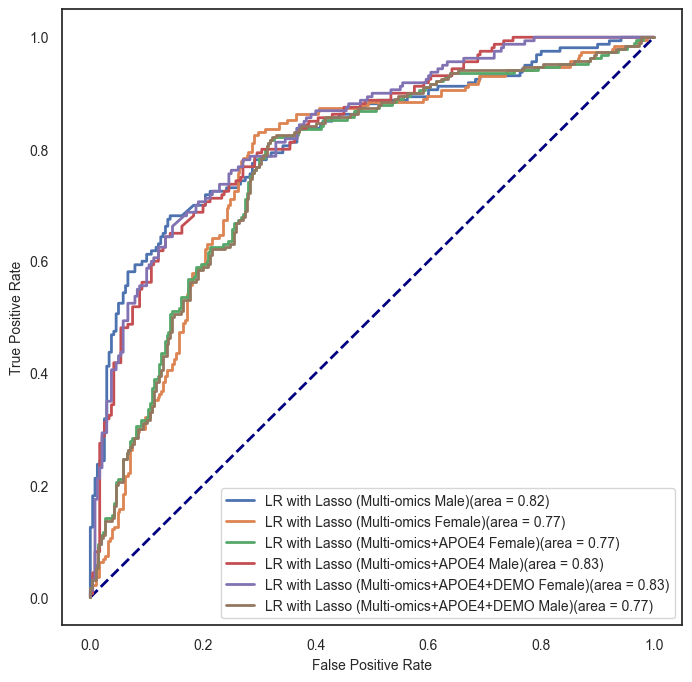

In [91]:
models = [
    {'y_true':  y_true_list_lr_omicsM, 'y_pred': y_pred_list_lr_omicsM, 'prob': y_pred_prob_list_lr_omicsM, 'label': 'LR with Lasso (Multi-omics Male)'},
    {'y_true':  y_true_list_lr_omicsF, 'y_pred': y_pred_list_lr_omicsF, 'prob': y_pred_prob_list_lr_omicsF, 'label': 'LR with Lasso (Multi-omics Female)'},
    {'y_true':  y_true_list_lr_omics_APOE4F, 'y_pred': y_pred_list_lr_omics_APOE4F, 'prob': y_pred_prob_list_lr_omics_APOE4F, 'label': 'LR with Lasso (Multi-omics+APOE4 Female)'},
    {'y_true':  y_true_list_lr_omics_APOE4M, 'y_pred': y_pred_list_lr_omics_APOE4M, 'prob': y_pred_prob_list_lr_omics_APOE4M, 'label': 'LR with Lasso (Multi-omics+APOE4 Male)'},
    {'y_true':  y_true_list_lr_omics_APOE4_demoM, 'y_pred': y_pred_list_lr_omics_APOE4_demoM, 'prob': y_pred_prob_list_lr_omics_APOE4_demoM, 'label': 'LR with Lasso (Multi-omics+APOE4+DEMO Female)'},
    {'y_true':  y_true_list_lr_omics_APOE4_demoF, 'y_pred': y_pred_list_lr_omics_APOE4_demoF, 'prob': y_pred_prob_list_lr_omics_APOE4_demoF, 'label': 'LR with Lasso (Multi-omics+APOE4+DEMO Male)'},

    ]



plt.figure(figsize=(8, 8))
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
for i, model in enumerate(models):
    fpr, tpr, _ = roc_curve(model['y_true'], model['prob'])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{model['label']}(area = {roc_auc:.2f})")
plt.xlabel('False Positive Rate', fontsize=10)
plt.ylabel('True Positive Rate', fontsize=10)
plt.legend(loc='lower right', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.savefig("../plots/AUC_performance2.pdf", format='pdf')
plt.show()